In [2]:
# Import essential libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Load the dataset
df = pd.read_csv("hr_employee_attrition.csv")
print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (5000, 16)
  EmployeeID  Age  Gender MaritalStatus EducationLevel             JobRole  \
0   EMP-1000   50    Male       Married      Doctorate     Sales Executive   
1   EMP-1001   36  Female       Married       Bachelor   Software Engineer   
2   EMP-1002   29    Male       Married       Bachelor             Manager   
3   EMP-1003   42    Male       Married       Bachelor  Research Scientist   
4   EMP-1004   40  Female      Divorced       Bachelor   Software Engineer   

   DistanceFromHome_KM  MonthlyIncome_BDT  YearsAtCompany  PercentSalaryHike  \
0                   15              64476              10                 23   
1                   12             170555               2                 20   
2                   16              91123               3                 11   
3                    6             145831               2                 22   
4                   28              74887              18                 21   

   JobSatisfaction  Envi

In [3]:
import scipy.stats as stats

# 2. A/B Testing (Chi-Square Test)
# Check if the retention policy (AB_RetentionGroup) has a significant impact on attrition
contingency_table = pd.crosstab(df["AB_RetentionGroup"], df["Attrition"])
print("\nContingency Table:")
print(contingency_table)

chi2, p_val, dof, ex = stats.chi2_contingency(contingency_table)
print(f"\nChi-square Statistic: {chi2:.4f}")
print(f"P-value: {p_val:.4f}")

if p_val < 0.05:
  print(
      "Result: Statistically significant! The retention policy is effective."
  )
else:
  print("Result: No statistically significant difference.")


Contingency Table:
Attrition             0   1
AB_RetentionGroup          
Control_A          2406  78
Treatment_B        2473  43

Chi-square Statistic: 10.2421
P-value: 0.0014
Result: Statistically significant! The retention policy is effective.


In [4]:
from sklearn.model_selection import train_test_split

# 3. Machine Learning Preprocessing
# Drop EmployeeID and apply one-hot encoding to categorical columns
df_model = pd.get_dummies(df.drop(columns=["EmployeeID"]), drop_first=True)

X = df_model.drop(columns=["Attrition"])
y = df_model["Attrition"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (4000, 21)
Testing Data Shape: (1000, 21)


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# 4. Random Forest Model Training and Evaluation
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
print("\n--- Random Forest Classification Report ---")
print(classification_report(y_test, y_pred_rf))
print(
    "Random Forest ROC-AUC Score:",
    roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1]),
)


--- Random Forest Classification Report ---
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       976
           1       0.00      0.00      0.00        24

    accuracy                           0.98      1000
   macro avg       0.49      0.50      0.49      1000
weighted avg       0.95      0.98      0.96      1000

Random Forest ROC-AUC Score: 0.6041239754098361


c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(

In [8]:
from xgboost import XGBClassifier

# Calculate a higher scale_pos_weight to give more weight to class 1
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_weight = neg_count / pos_count * 1.5  # Multiplying by 1.5 for better sensitivity

# Initialize XGBoost with tuned scale_pos_weight (removed deprecated use_label_encoder)
xgb_model = XGBClassifier(
    eval_metric="logloss",
    scale_pos_weight=scale_weight,
    random_state=42
)
xgb_model.fit(X_train, y_train)

# Adjusting prediction threshold to 0.3 instead of default 0.5 to catch class 1
y_probs = xgb_model.predict_proba(X_test)[:, 1]
y_pred_xgb = (y_probs >= 0.3).astype(int)

print("\n--- XGBoost Classification Report (With Adjusted Threshold) ---")
print(classification_report(y_test, y_pred_xgb))
print("XGBoost ROC-AUC Score:", roc_auc_score(y_test, y_probs))


--- XGBoost Classification Report (With Adjusted Threshold) ---
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       976
           1       0.00      0.00      0.00        24

    accuracy                           0.96      1000
   macro avg       0.49      0.49      0.49      1000
weighted avg       0.95      0.96      0.96      1000

XGBoost ROC-AUC Score: 0.6401127049180327


In [9]:
!pip install imbalanced-learn


   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   ---------------------------------------- 2/2 [imbalanced-learn]




[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, roc_auc_score
from xgboost import XGBClassifier

# Apply SMOTE to handle class imbalance in the training set
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

# Train the XGBoost model on the resampled data
xgb_model = XGBClassifier(eval_metric="logloss", random_state=42)
xgb_model.fit(X_train_res, y_train_res)

# Generate predictions and evaluation report on the test set
y_pred_xgb = xgb_model.predict(X_test)
print("\n--- XGBoost Classification Report (With SMOTE) ---")
print(classification_report(y_test, y_pred_xgb))
print(
    "XGBoost ROC-AUC Score:",
    roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:, 1]),
)


--- XGBoost Classification Report (With SMOTE) ---
              precision    recall  f1-score   support

           0       0.98      0.97      0.97       976
           1       0.04      0.04      0.04        24

    accuracy                           0.95      1000
   macro avg       0.51      0.51      0.51      1000
weighted avg       0.95      0.95      0.95      1000

XGBoost ROC-AUC Score: 0.5614754098360656


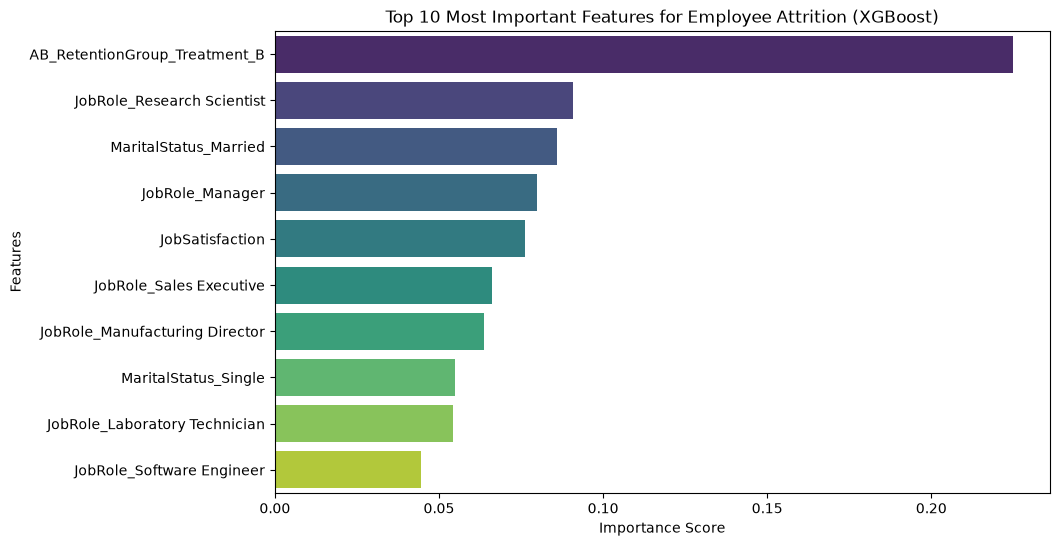

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Plot the top 10 most important features from the trained XGBoost model
feature_imp = pd.Series(
    xgb_model.feature_importances_, index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=feature_imp[:10],
    y=feature_imp.index[:10],
    hue=feature_imp.index[:10],
    palette="viridis",
    legend=False,
)
plt.title(
    "Top 10 Most Important Features for Employee Attrition (XGBoost)", fontsize=12
)
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

In [12]:
import pandas as pd

# Find the indices of employees predicted as Attrition (Class 1)
risky_indices = np.where(y_pred_xgb == 1)[0]

# Retrieve their original details from the test set
risky_employees = X_test.iloc[risky_indices]

print(f"Total risky employees identified: {len(risky_indices)}")
print(risky_employees.head())

Total risky employees identified: 28
      Age  DistanceFromHome_KM  MonthlyIncome_BDT  YearsAtCompany  \
1936   38                    4              88816              20   
2753   29                    9             152037               9   
4092   43                   10              80226               4   
2308   45                   15             155557              11   
4173   29                   15             122930              15   

      PercentSalaryHike  JobSatisfaction  EnvironmentSatisfaction  \
1936                 14                3                        3   
2753                 16                2                        3   
4092                 20                1                        1   
2308                 16                3                        1   
4173                 16                1                        3   

      WorkLifeBalance  Gender_Male  MaritalStatus_Married  ...  \
1936                2         True                  False  ...   
2